
# Medical Insurance Cost Prediction

## Goal

Build Machine Learning models to predict individual medical insurance charges based on customer characteristics.

## Audience and purpose

This project is for learning and understanding how Machine Learning can be used to make predictions from real-world data, It builds on the previous Medical Insurance Charges Analysis project, moving from exploring historical patterns to predicting charges for unseen customers.

## Prediction task

- Learning type: Supervised Learning
- Problem type: Regression
- Input features (X): age, sex, bmi, children, smoker, region
- Target variable (y): charges

## Questions

- Can customer characteristics be used to predict medical insurance charges ?
- How accurately can Machine Learning models predict these charges ?
- Which Regression models perform best on unseen data ?
- Which features are most useful for making predictions ?

This project focuses on prediction, not proving cause and effect, Model predictions are estimates based on historical data, not actual insurance quotations.


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
df = pd.read_csv("insurance.csv")

### 1 - Cleaning data

In [33]:
null_values = df.isnull().sum().sum()
print("Number of null values : ", null_values)

Number of null values :  0


In [34]:
df = df.drop_duplicates().reset_index(drop=True)
df.duplicated().any()

np.False_

### 2 - Define Features and Target

In [35]:
X = df.drop(columns=["charges"])
y = df["charges"]

In [36]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1337, 6)
Target shape: (1337,)


### 3 - Train-Test Split

In [37]:
from sklearn.model_selection import train_test_split

In [38]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

In [39]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (1069, 6)
Testing features: (268, 6)


In [40]:
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training target: (1069,)
Testing target: (268,)


### 4 - Data Preprocessing

#### 4.1 - Feature Types Inspection

In [41]:
print(X_train.dtypes)

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
dtype: object


In [42]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

In [43]:
print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['age', 'bmi', 'children']
Categorical features: ['sex', 'smoker', 'region']


#### 4.2 - Encoding and Scaling

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder( drop="first", handle_unknown="ignore", sparse_output=False ), categorical_features)
    ]
)

In [46]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [47]:
feature_names = preprocessor.get_feature_names_out()

In [48]:
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("\nProcessed feature names:\n", feature_names)


Training shape: (1069, 8)
Testing shape: (268, 8)

Processed feature names:
 ['num__age' 'num__bmi' 'num__children' 'cat__sex_male' 'cat__smoker_yes'
 'cat__region_northwest' 'cat__region_southeast' 'cat__region_southwest']



#### 4.3 - Verify Preprocessing

In [49]:
X_train_processed_df = pd.DataFrame( X_train_processed, columns=feature_names, index=X_train.index )

In [50]:
X_train_processed_df.head()

,num__age,num__bmi,num__children,cat__sex_male,cat__smoker_yes,cat__region_northwest,cat__region_southeast,cat__region_southwest
1113,-1.157680,-0.996928,-0.907908,1.0,0.0,0.0,0.0,0.0
967,-1.300619,-0.792762,0.766904,1.0,0.0,0.0,0.0,0.0
598,0.914926,1.154664,0.766904,0.0,0.0,1.0,0.0,0.0
170,1.701087,1.806837,-0.907908,1.0,0.0,0.0,1.0,0.0
275,0.557580,-0.651417,0.766904,0.0,0.0,0.0,0.0,0.0


In [51]:
print("Numerical feature means:")
print(X_train_processed_df[["num__age", "num__bmi", "num__children"]].mean().round(3))

Numerical feature means:
num__age         0.0
num__bmi         0.0
num__children    0.0
dtype: float64


In [52]:
print("\nNumerical feature standard deviations:")
print(X_train_processed_df[["num__age", "num__bmi", "num__children"]].std(ddof=0).round(3))


Numerical feature standard deviations:
num__age         1.0
num__bmi         1.0
num__children    1.0
dtype: float64


### 5 - Baseline Model

In [53]:
from sklearn.dummy import DummyRegressor

In [ ]:
baseline_model = DummyRegressor(strategy="mean")    # baseline model

In [56]:
baseline_model.fit(X_train_processed, y_train)      # Train the model

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None


In [57]:
y_pred_baseline = baseline_model.predict(X_test_processed)    # Generate predictions on test data

In [64]:
print("Baseline prediction:", y_pred_baseline[0])
print("First 5 predictions:", y_pred_baseline[:3])

Baseline prediction: 13030.203369289055
First 5 predictions: [13030.20336929 13030.20336929 13030.20336929]


#### 5.1 - Baseline Evaluation

In [65]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [66]:
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_mse = mean_squared_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, y_pred_baseline)

In [67]:
print(f"Baseline MAE:  ${baseline_mae:.2f}")
print(f"Baseline MSE:  {baseline_mse:.2f}")
print(f"Baseline RMSE: ${baseline_rmse:.2f}")
print(f"Baseline R²:   {baseline_r2:.4f}")

Baseline MAE:  $9861.80
Baseline MSE:  185298141.69
Baseline RMSE: $13612.43
Baseline R²:   -0.0084


### 6 - Linear Regression

In [68]:
from sklearn.linear_model import LinearRegression

In [69]:
linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)
y_pred_linear = linear_model.predict(X_test_processed)

In [71]:
print("Bias (Intercept):", linear_model.intercept_)

Bias (Intercept): 8947.95219506918


In [74]:
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Weight": linear_model.coef_
})

coefficients.sort_values( by="Weight", key=abs, ascending=False )

,Feature,Weight
4,cat__smoker_yes,23077.764593
0,num__age,3472.975553
1,num__bmi,1927.828251
6,cat__region_southeast,-838.919616
7,cat__region_southwest,-659.139752
2,num__children,636.501185
5,cat__region_northwest,-391.761455
3,cat__sex_male,-101.542054


In [85]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_linear,
    "Loss": np.abs(y_test - y_pred_linear).round(1)
})

comparison.sort_values(by="Loss", ascending=False).head()

,Actual,Predicted,Loss
543,63770.42801,39659.206889,24111.2
818,55135.40209,31107.766807,24027.6
1229,60021.39897,36988.215397,23033.2
986,28340.18885,9028.579983,19311.6
115,30259.99556,12811.716568,17448.3


#### 6.1 - Linear Regression Evaluation

* Compare its performance with the baseline model to determine

In [ ]:
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_mse = mean_squared_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, y_pred_linear)

In [82]:
model_comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [baseline_mae, linear_mae],
    "MSE": [baseline_mse, linear_mse],
    "RMSE": [baseline_rmse, linear_rmse],
    "R2": [baseline_r2, linear_r2]
})

In [83]:
model_comparison.round(4)

,Model,MAE,MSE,RMSE,R2
0,Baseline,9861.7979,1.852981e+08,13612.4260,-0.0084
1,Linear Regression,4177.0456,3.547802e+07,5956.3429,0.8069


- **MAE** decreased by approximately **57.6%**.
- **RMSE** decreased by approximately **56.2%**.
- **R²** improved to **0.8069** from a negative value, meaning the model explains approximately **80.69%** of the variance in the charges values within the test data.

#### 6.2 Residual Analysis

Analyze the differences between actual and predicted insurance charges to identify prediction patterns and potential model limitations.

In [86]:
residuals = y_test - y_pred_linear

In [87]:
residuals_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_linear,
    "Residual": residuals
})

residuals_df.head()

,Actual,Predicted,Residual
899,8688.85885,8143.693884,545.164966
1063,5708.86700,5737.115683,-28.248683
1255,11436.73815,14369.314876,-2932.576726
298,38746.35510,31745.513636,7000.841464
237,4463.20510,8962.386657,-4499.181557


In [88]:
print("Mean Residual:", residuals.mean())
print("Minimum Residual:", residuals.min())
print("Maximum Residual:", residuals.max())

Mean Residual: 425.2569948432542
Minimum Residual: -10314.509078071678
Maximum Residual: 24111.221121119786


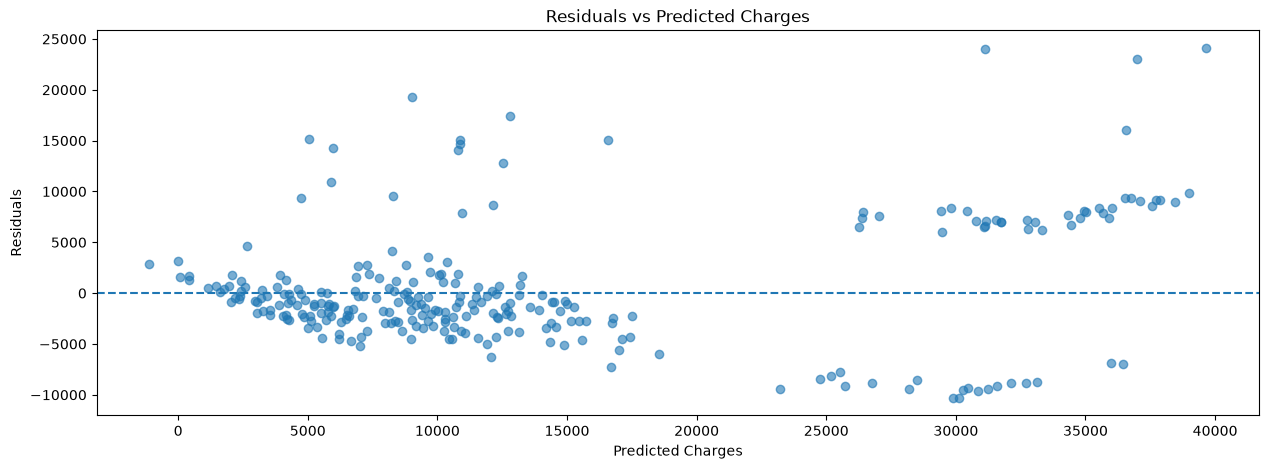

In [97]:

plt.figure(figsize=(15, 5))
plt.scatter(y_pred_linear, residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Charges")

plt.show()


##### Conclusion

- Linear Regression provides a strong improvement over the baseline model
- but its residual patterns suggest that a simple linear relationship may not capture all the patterns in medical insurance charges
- Further feature engineering and model experiments may improve its performance.


#### 6.3 - Feature Engineering: Smoker-BMI Interaction

Create an interaction feature between BMI and smoking status to allow the Linear Regression model to capture different BMI effects for smokers and non-smokers.


In [98]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

In [99]:
X_train_fe["smoker_bmi"] = ( X_train_fe["bmi"] * (X_train_fe["smoker"] == "yes").astype(int) )

In [100]:
X_test_fe["smoker_bmi"] = ( X_test_fe["bmi"] * (X_test_fe["smoker"] == "yes").astype(int) )

In [103]:
X_train_fe[["bmi", "smoker", "smoker_bmi"]].sample(5)

,bmi,smoker,smoker_bmi
747,36.00,no,0.00
830,25.84,no,0.00
153,23.37,yes,23.37
842,29.81,yes,29.81
352,27.70,no,0.00


In [104]:
print("New training shape:", X_train_fe.shape)
print("New testing shape:", X_test_fe.shape)


New training shape: (1069, 7)
New testing shape: (268, 7)


#### 6.4 - Preprocessing Engineered Features

Extend the preprocessing transformations to include the new smoker-BMI interaction feature while keeping the original categorical encoding.

In [105]:
numeric_features_fe = numeric_features + ["smoker_bmi"]

In [107]:
preprocessor_fe = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_fe),
        ("cat", OneHotEncoder( drop="first", handle_unknown="ignore", sparse_output=False ), categorical_features)
    ]
)

In [108]:
X_train_fe_processed = preprocessor_fe.fit_transform(X_train_fe)
X_test_fe_processed = preprocessor_fe.transform(X_test_fe)

In [109]:
feature_names_fe = preprocessor_fe.get_feature_names_out()
print("Training shape:", X_train_fe_processed.shape)
print("Testing shape:", X_test_fe_processed.shape)

Training shape: (1069, 9)
Testing shape: (268, 9)



#### 6.5 - Linear Regression with Feature Engineering

Train a new Linear Regression model using the engineered features, including the smoker-BMI interaction.

Compare its performance with the original Linear Regression model to evaluate whether the new feature improves prediction quality.

In [110]:
linear_model_fe = LinearRegression()
linear_model_fe.fit(X_train_fe_processed, y_train)
y_pred_linear_fe = linear_model_fe.predict(X_test_fe_processed)

In [112]:
print("Engineered model bias:", linear_model_fe.intercept_)
print("Number of learned weights:", len(linear_model_fe.coef_))

Engineered model bias: 18272.849245849327
Number of learned weights: 9


* Now Evaluate the new model

In [113]:
fe_mae = mean_absolute_error(y_test, y_pred_linear_fe)
fe_mse = mean_squared_error(y_test, y_pred_linear_fe)
fe_rmse = np.sqrt(fe_mse)
fe_r2 = r2_score(y_test, y_pred_linear_fe)

In [ ]:
feature_engineering_comparison = pd.DataFrame({
    "Model": [
        "Original Linear Regression", "Linear Regression + smoker_bmi"
    ],
    "MAE": [linear_mae, fe_mae],
    "MSE": [linear_mse, fe_mse],
    "RMSE": [linear_rmse, fe_rmse],
    "R2": [linear_r2, fe_r2]
})

In [116]:
feature_engineering_comparison.round(4)

,Model,MAE,MSE,RMSE,R2
0,Original Linear Regression,4177.0456,3.547802e+07,5956.3429,0.8069
1,Linear Regression + smoker_bmi,2828.9737,2.091060e+07,4572.8112,0.8862


##### Observations - Smoker-BMI Interaction

- Adding the `smoker_bmi` interaction feature significantly **improved Linear Regression performance**.
- MAE decreased from approximately **$4,177** to **$2,829** (32.3% reduction).
- RMSE decreased from approximately **$5,956** to **$4,573** (23.2% reduction).
- R² increased from **0.8069** to **0.8862**.
- The interaction feature allows the model to represent different **BMI** relationships for **smokers** and **non-smokers**.

##### Conclusion

- The `smoker_bmi` feature provides useful additional information for predicting medical insurance charges
- The engineered Linear Regression model performs better than the original model on the evaluated test set.


#### 6.6 - Generalization Check

Compare training and testing performance to investigate whether the engineered Linear Regression model generalizes well to unseen observations.


In [117]:
y_pred_train_fe = linear_model_fe.predict(X_train_fe_processed)

In [118]:
train_mae_fe = mean_absolute_error(y_train, y_pred_train_fe)
train_rmse_fe = np.sqrt(mean_squared_error(y_train, y_pred_train_fe))
train_r2_fe = r2_score(y_train, y_pred_train_fe)

In [119]:
generalization_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [train_mae_fe, fe_mae],
    "RMSE": [train_rmse_fe, fe_rmse],
    "R2": [train_r2_fe, fe_r2]
})

generalization_results.round(4)


,Dataset,MAE,RMSE,R2
0,Training,2967.9824,4898.7002,0.8247
1,Testing,2828.9737,4572.8112,0.8862



#### Generalization Observations

- Training and testing performance are relatively close.
- The model achieves slightly lower MAE and RMSE on the test set.
- The test **R² (0.8862)** is higher than the training **R² (0.8247)**.
- There is **no clear indication of overfitting** in this train-test comparison.
- The difference may be due to the test samples being easier to predict than some training observations.

#### Conclusion

- The engineered Linear Regression model shows reasonable generalization on this particular split.
- Cross-validation will be used in later experiments to obtain a more reliable estimate of model performance.



#### 6.7 - Inspect Engineered Model Coefficients

Examine the learned coefficients of the engineered Linear Regression model to understand how the interaction feature contributes to predictions.


In [120]:
coefficients_fe = pd.DataFrame({
    "Feature": feature_names_fe,
    "Weight": linear_model_fe.coef_
})

In [121]:
coefficients_fe.sort_values( by="Weight",  key=abs, ascending=False )

,Feature,Weight
5,cat__smoker_yes,-21687.830077
3,num__smoker_bmi,18355.436758
0,num__age,3624.555493
7,cat__region_southeast,-895.669808
8,cat__region_southwest,-884.564628
2,num__children,680.722998
4,cat__sex_male,-647.366040
6,cat__region_northwest,-438.161448
1,num__bmi,75.564129



#### 6.8 - Residual Comparison

Compare the residual distributions of the original and engineered Linear Regression models to investigate how the interaction feature affects prediction errors.


In [122]:
residuals_original = y_test - y_pred_linear
residuals_fe = y_test - y_pred_linear_fe

In [124]:
residual_comparison = pd.DataFrame({
    "Model": ["Original Linear Regression","Linear Regression + smoker_bmi"],
    
    "Mean Residual": [
        residuals_original.mean(),
        residuals_fe.mean()
    ],
    "Minimum Residual": [
        residuals_original.min(),
        residuals_fe.min()
    ],
    "Maximum Residual": [
        residuals_original.max(),
        residuals_fe.max()
    ],
    "MAE": [linear_mae, fe_mae],
    "RMSE": [linear_rmse, fe_rmse]
})


In [125]:
residual_comparison.round(2)

,Model,Mean Residual,Minimum Residual,Maximum Residual,MAE,RMSE
0,Original Linear Regression,425.26,-10314.51,24111.22,4177.05,5956.34
1,Linear Regression + smoker_bmi,-44.37,-11083.69,20812.98,2828.97,4572.81


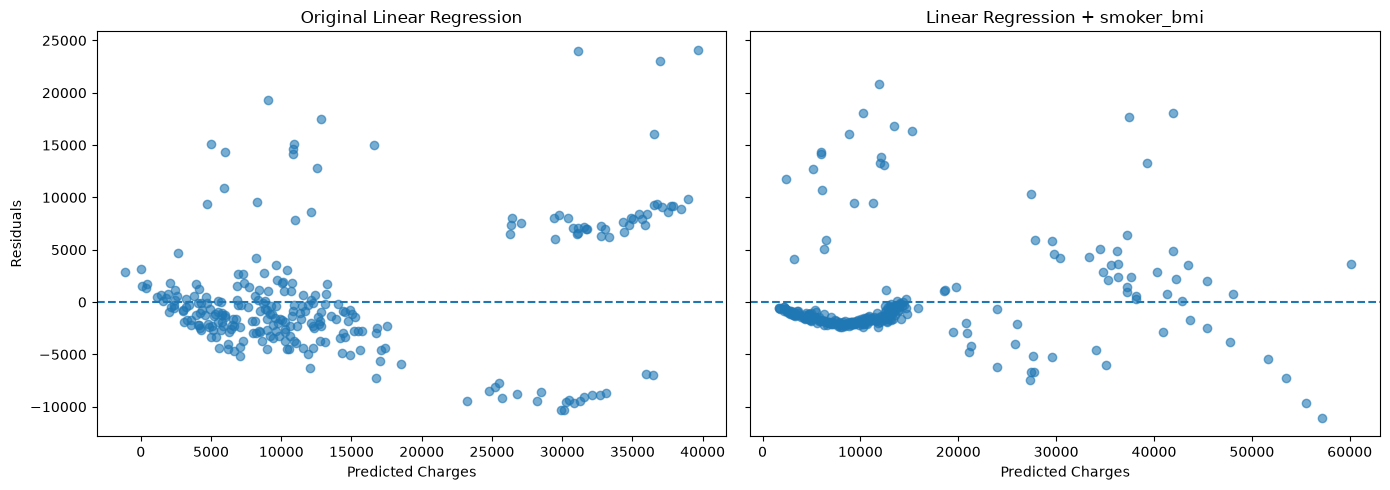

In [126]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Original model
axes[0].scatter(y_pred_linear, residuals_original, alpha=0.6)
axes[0].axhline(y=0, linestyle="--")
axes[0].set_title("Original Linear Regression")
axes[0].set_xlabel("Predicted Charges")
axes[0].set_ylabel("Residuals")

# Engineered model
axes[1].scatter(y_pred_linear_fe, residuals_fe, alpha=0.6)
axes[1].axhline(y=0, linestyle="--")
axes[1].set_title("Linear Regression + smoker_bmi")
axes[1].set_xlabel("Predicted Charges")

plt.tight_layout()
plt.show()



### Residual Analysis Conclusion

- The `smoker_bmi` interaction feature improved overall prediction performance.
- MAE decreased by approximately **32.3%**, while RMSE decreased by approximately **23.2%**.
- The mean residual moved closer to zero, indicating less average signed prediction bias on the test set.
- The largest positive residual decreased, while the largest negative residual became slightly more extreme.
- Residuals still show substantial errors at higher predicted charges, suggesting that the model does not capture all patterns in expensive insurance cases.

**Conclusion:** The interaction feature provides useful information and improves Linear Regression performance, although some prediction limitations remain.



### 7 - Cross-Validation

Use 5-Fold Cross-Validation to evaluate the original and engineered Linear Regression models across multiple training and validation splits.

The preprocessing and feature engineering steps are included in pipelines to prevent data leakage during validation.

In [127]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import KFold, cross_validate

In [128]:
def add_smoker_bmi(data):
    data = data.copy()
    data["smoker_bmi"] = ( data["bmi"] * (data["smoker"] == "yes").astype(int) )
    return data

In [ ]:
preprocessor_original_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder( drop="first", handle_unknown="ignore", sparse_output=False ), categorical_features)
    ]
)

In [ ]:
preprocessor_interaction_cv = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features + ["smoker_bmi"]),
        ("cat", OneHotEncoder( drop="first", handle_unknown="ignore", sparse_output=False ), categorical_features)
    ]
)

In [131]:
original_pipeline = Pipeline([
    ("preprocessing", preprocessor_original_cv),
    ("model", LinearRegression())
])

In [ ]:
interaction_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(add_smoker_bmi, validate=False)),
    ("preprocessing", preprocessor_interaction_cv),
    ("model", LinearRegression())
])

#### 7.1 - Run 5-Fold Cross-Validation

In [134]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [135]:
scoring = { "MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2" }

In [136]:
original_cv_results = cross_validate( original_pipeline, X_train, y_train, cv=cv, scoring=scoring )

In [137]:
interaction_cv_results = cross_validate( interaction_pipeline, X_train, y_train, cv=cv, scoring=scoring )

#### 7.2 — Compare Cross-Validation Results

In [138]:
cv_comparison = pd.DataFrame({
    "Model": [
        "Original Linear Regression",
        "Linear Regression + smoker_bmi"
    ],
    "Mean MAE": [
        -original_cv_results["test_MAE"].mean(),
        -interaction_cv_results["test_MAE"].mean()
    ],
    "Mean RMSE": [
        -original_cv_results["test_RMSE"].mean(),
        -interaction_cv_results["test_RMSE"].mean()
    ],
    "Mean R2": [
        original_cv_results["test_R2"].mean(),
        interaction_cv_results["test_R2"].mean()
    ]
})


In [139]:
cv_comparison.round(4)

,Model,Mean MAE,Mean RMSE,Mean R2
0,Original Linear Regression,4221.9633,6123.6513,0.7228
1,Linear Regression + smoker_bmi,2992.7284,4943.0134,0.8188



#### Cross-Validation Observations

- The engineered Linear Regression model achieved better average performance across the five validation folds.
- Mean MAE decreased from **$4,221.96** to **$2,992.73** (approximately **29.1%**).
- Mean RMSE decreased from **$6,123.65** to **$4,943.01** (approximately **19.3%**).
- Mean R² increased from **0.7228** to **0.8188**.
- The improvement across cross-validation suggests that the `smoker_bmi` interaction feature provides useful information beyond the original features.

#### Conclusion

The `smoker_bmi` interaction feature improves the average validation performance of Linear Regression. It will be retained for the next experiments, while further validation will be used to assess model stability.


#### 7.3 Final observations: Interaction Feature